Training samples: (1400, 64)
Testing samples: (300, 64)

Training: CD-1
CD-1 | Epoch 1/10 | Recon Error=0.1647 | Pseudo-LL=-1.7059
CD-1 | Epoch 2/10 | Recon Error=0.1328 | Pseudo-LL=-1.2063
CD-1 | Epoch 3/10 | Recon Error=0.1299 | Pseudo-LL=-1.0454
CD-1 | Epoch 4/10 | Recon Error=0.1290 | Pseudo-LL=-3.2918
CD-1 | Epoch 5/10 | Recon Error=0.1287 | Pseudo-LL=-0.7376
CD-1 | Epoch 6/10 | Recon Error=0.1285 | Pseudo-LL=-0.7234
CD-1 | Epoch 7/10 | Recon Error=0.1286 | Pseudo-LL=-3.8725
CD-1 | Epoch 8/10 | Recon Error=0.1284 | Pseudo-LL=-1.2866
CD-1 | Epoch 9/10 | Recon Error=0.1283 | Pseudo-LL=-0.7395
CD-1 | Epoch 10/10 | Recon Error=0.1283 | Pseudo-LL=-0.6923

Training: CD-5
CD-5 | Epoch 1/10 | Recon Error=0.1630 | Pseudo-LL=-0.7957
CD-5 | Epoch 2/10 | Recon Error=0.1324 | Pseudo-LL=-2.7972
CD-5 | Epoch 3/10 | Recon Error=0.1299 | Pseudo-LL=-0.8395
CD-5 | Epoch 4/10 | Recon Error=0.1291 | Pseudo-LL=-0.7293
CD-5 | Epoch 5/10 | Recon Error=0.1287 | Pseudo-LL=-1.4364
CD-5 | Epoch 6/10 | Recon 

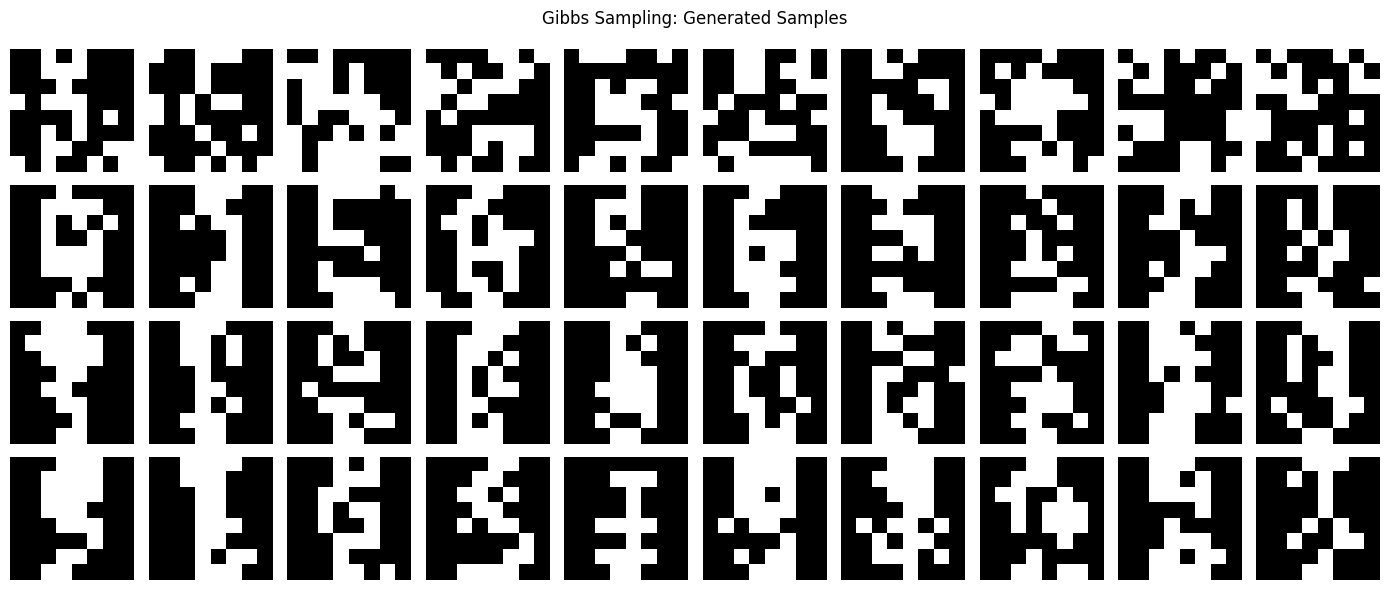

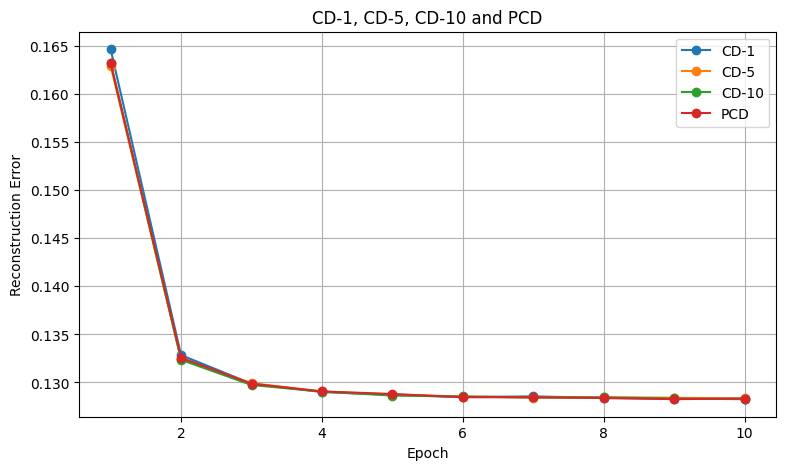

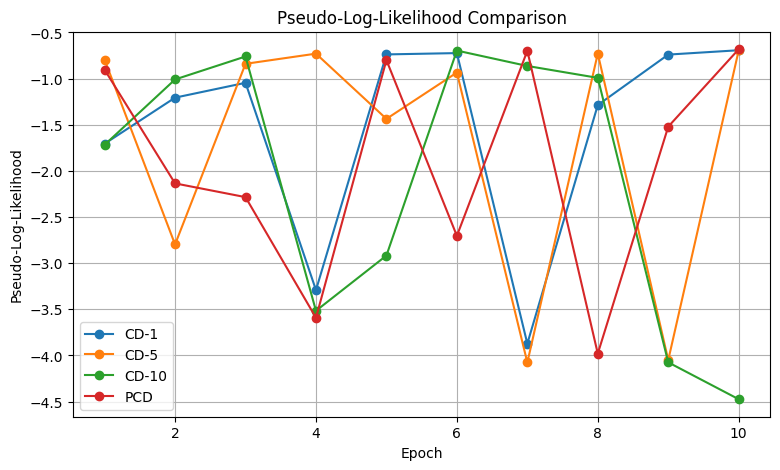

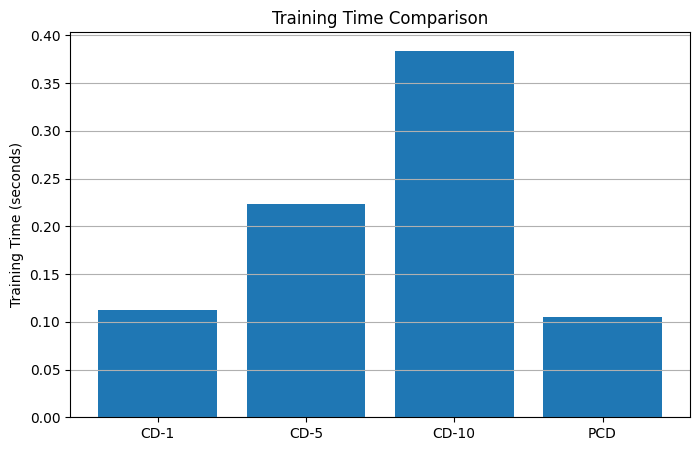

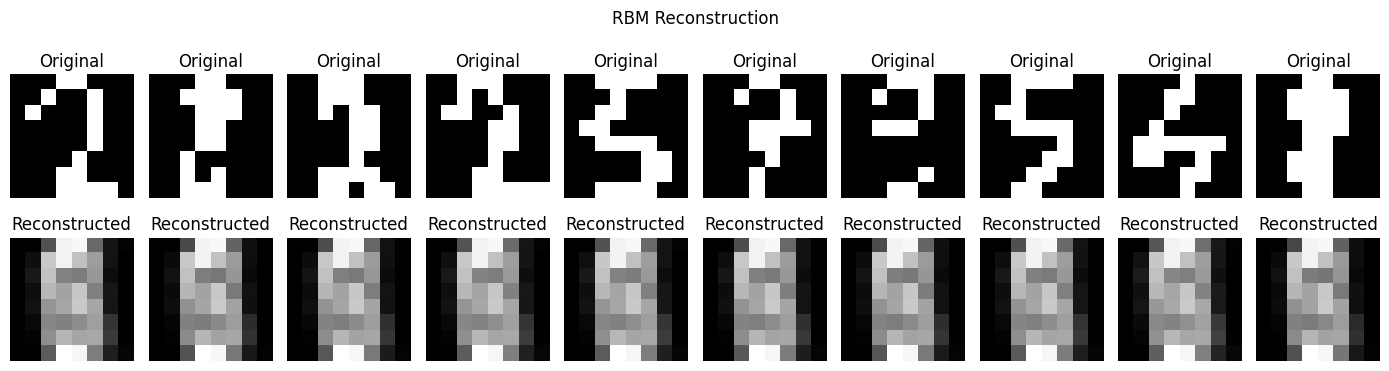


===== FINAL COMPARISON =====
Method  Final Reconstruction Error  Final Pseudo-Log-Likelihood  Training Time (s)
  CD-1                      0.1283                      -0.6923             0.1119
  CD-5                      0.1283                      -0.6940             0.2230
 CD-10                      0.1283                      -4.4748             0.3839
   PCD                      0.1283                      -0.6814             0.1051

EXPERIMENT 26 COMPLETED SUCCESSFULLY


In [9]:
# EXPERIMENT 26: GIBBS SAMPLING AND CONTRASTIVE DIVERGENCE ANALYSIS
# CD-1 vs CD-5 vs CD-10 vs Persistent CD (PCD)

import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_digits

np.random.seed(42)

# --------------------------------------------------
# 1. LOAD AND BINARIZE DIGITS DATA
# --------------------------------------------------
digits = load_digits()
X = digits.data.astype(np.float32) / 16.0
X = (X > 0.5).astype(np.float32)

X_train = X[:1400]
X_test = X[1400:1700]

n_visible = 64
n_hidden = 32
lr = 0.03
epochs = 10
batch_size = 64

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

# --------------------------------------------------
# 2. RBM FUNCTIONS
# --------------------------------------------------
def sigmoid(x):
    x = np.clip(x, -40, 40)
    return 1 / (1 + np.exp(-x))

class RBM:
    def __init__(self, n_visible, n_hidden, lr=0.03):
        self.W = np.random.normal(
            0, 0.01, (n_visible, n_hidden)
        )
        self.vb = np.zeros(n_visible)
        self.hb = np.zeros(n_hidden)
        self.lr = lr

    def ph(self, v):
        return sigmoid(v @ self.W + self.hb)

    def pv(self, h):
        return sigmoid(h @ self.W.T + self.vb)

    def sample(self, p):
        return (np.random.rand(*p.shape) < p).astype(np.float32)

    def gibbs(self, v):
        ph = self.ph(v)
        h = self.sample(ph)
        pv = self.pv(h)
        v_new = self.sample(pv)
        return v_new, pv, ph

    def free_energy(self, v):
        return -(v @ self.vb) - np.logaddexp(
            0, v @ self.W + self.hb
        ).sum(axis=1)

    def pseudo_log_likelihood(self, v):
        # Randomly flip one visible bit per sample
        bit = np.random.randint(0, v.shape[1])
        v_flip = v.copy()
        v_flip[np.arange(len(v)), bit] = (
            1 - v_flip[np.arange(len(v)), bit]
        )

        F_original = self.free_energy(v)
        F_flip = self.free_energy(v_flip)

        return np.mean(-np.logaddexp(0, F_flip - F_original))

# --------------------------------------------------
# 3. TRAIN RBM: CD-k OR PERSISTENT CD
# --------------------------------------------------
def train_rbm(method, k, epochs=10):
    rbm = RBM(n_visible, n_hidden, lr)

    persistent_v = np.random.binomial(
        1, 0.5, (batch_size, n_visible)
    ).astype(np.float32)

    errors = []
    pll_values = []
    training_times = []

    start_time = time.time()

    for epoch in range(epochs):
        np.random.shuffle(X_train)
        epoch_errors = []

        for start in range(0, len(X_train), batch_size):
            batch = X_train[start:start+batch_size]
            b = len(batch)

            # Positive phase
            ph0 = rbm.ph(batch)
            h0 = rbm.sample(ph0)

            # Negative phase initialization
            if method == "PCD":
                v_chain = persistent_v[:b].copy()
            else:
                v_chain = batch.copy()

            # k-step Gibbs sampling
            for step in range(k):
                ph = rbm.ph(v_chain)
                h_chain = rbm.sample(ph)
                pv = rbm.pv(h_chain)
                v_chain = rbm.sample(pv)

            phk = rbm.ph(v_chain)

            # Weight update
            rbm.W += rbm.lr * (
                batch.T @ ph0 - v_chain.T @ phk
            ) / b

            rbm.vb += rbm.lr * np.mean(
                batch - v_chain, axis=0
            )

            rbm.hb += rbm.lr * np.mean(
                ph0 - phk, axis=0
            )

            if method == "PCD":
                persistent_v[:b] = v_chain

            # Reconstruction error
            reconstructed = rbm.pv(rbm.ph(batch))
            epoch_errors.append(
                np.mean((batch - reconstructed) ** 2)
            )

        errors.append(np.mean(epoch_errors))

        pll = rbm.pseudo_log_likelihood(X_test[:100])
        pll_values.append(pll)

        training_times.append(time.time() - start_time)

        print(
            f"{method} | Epoch {epoch+1}/{epochs} | "
            f"Recon Error={errors[-1]:.4f} | "
            f"Pseudo-LL={pll:.4f}"
        )

    total_time = time.time() - start_time

    return rbm, errors, pll_values, total_time

# --------------------------------------------------
# 4. TRAIN CD-1, CD-5, CD-10 AND PCD
# --------------------------------------------------
results = {}

configs = [
    ("CD-1", 1),
    ("CD-5", 5),
    ("CD-10", 10),
    ("PCD", 1)
]

for method, k in configs:
    print("\nTraining:", method)
    rbm, errors, pll, elapsed = train_rbm(
        method, k, epochs=epochs
    )

    results[method] = {
        "rbm": rbm,
        "errors": errors,
        "pll": pll,
        "time": elapsed
    }

# --------------------------------------------------
# 5. GIBBS CHAIN VISUALIZATION
# Use the trained CD-1 model and random initial images
# --------------------------------------------------
sample_rbm = results["CD-1"]["rbm"]

v_chain = np.random.binomial(
    1, 0.5, (10, n_visible)
).astype(np.float32)

steps_to_show = [1, 10, 100, 1000]
chain_samples = {}

for step in range(1, max(steps_to_show) + 1):
    v_chain, _, _ = sample_rbm.gibbs(v_chain)

    if step in steps_to_show:
        chain_samples[step] = v_chain.copy()

# Display samples at different Gibbs steps
fig, axes = plt.subplots(
    len(steps_to_show), 10, figsize=(14, 6)
)

for row, step in enumerate(steps_to_show):
    for col in range(10):
        axes[row, col].imshow(
            chain_samples[step][col].reshape(8, 8),
            cmap="gray"
        )
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        f"{step} Steps", fontsize=10
    )

plt.suptitle("Gibbs Sampling: Generated Samples")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. RECONSTRUCTION ERROR COMPARISON
# --------------------------------------------------
plt.figure(figsize=(9, 5))

for method in results:
    plt.plot(
        range(1, epochs+1),
        results[method]["errors"],
        marker="o",
        label=method
    )

plt.xlabel("Epoch")
plt.ylabel("Reconstruction Error")
plt.title("CD-1, CD-5, CD-10 and PCD")
plt.grid(True)
plt.legend()
plt.show()

# --------------------------------------------------
# 7. PSEUDO-LOG-LIKELIHOOD COMPARISON
# --------------------------------------------------
plt.figure(figsize=(9, 5))

for method in results:
    plt.plot(
        range(1, epochs+1),
        results[method]["pll"],
        marker="o",
        label=method
    )

plt.xlabel("Epoch")
plt.ylabel("Pseudo-Log-Likelihood")
plt.title("Pseudo-Log-Likelihood Comparison")
plt.grid(True)
plt.legend()
plt.show()

# --------------------------------------------------
# 8. TRAINING TIME COMPARISON
# --------------------------------------------------
methods = list(results.keys())
times = [results[m]["time"] for m in methods]

plt.figure(figsize=(8, 5))
plt.bar(methods, times)

plt.ylabel("Training Time (seconds)")
plt.title("Training Time Comparison")
plt.grid(axis="y")
plt.show()

# --------------------------------------------------
# 9. ORIGINAL VS RECONSTRUCTED IMAGES
# --------------------------------------------------
original = X_test[:10]

reconstructed = sample_rbm.pv(
    sample_rbm.ph(original)
)

fig, axes = plt.subplots(2, 10, figsize=(14, 4))

for i in range(10):
    axes[0, i].imshow(
        original[i].reshape(8, 8), cmap="gray"
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        reconstructed[i].reshape(8, 8), cmap="gray"
    )
    axes[1, i].set_title("Reconstructed")
    axes[1, i].axis("off")

plt.suptitle("RBM Reconstruction")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. RESULTS TABLE
# --------------------------------------------------
summary = []

for method in results:
    summary.append({
        "Method": method,
        "Final Reconstruction Error": results[method]["errors"][-1],
        "Final Pseudo-Log-Likelihood": results[method]["pll"][-1],
        "Training Time (s)": results[method]["time"]
    })

summary_df = pd.DataFrame(summary)

print("\n===== FINAL COMPARISON =====")
print(summary_df.round(4).to_string(index=False))

print("\nEXPERIMENT 26 COMPLETED SUCCESSFULLY")